# CORRECTED NOTEBOOK -- re-run with *Kernel > Restart & Run All*

Only these lines were changed (everything else is identical to the original):

- cell 33: cis-dihydrocarvone SMILES corrected (was another molecule)

All outputs were cleared because the scores of the corrected compounds change.

# Molecular docking -- Mentha_spicata vs ACE (1O86)



In [1]:
from pymol import cmd
import py3Dmol

from vina import Vina

from openbabel import pybel

from rdkit import Chem
from rdkit.Chem import AllChem, Draw

from meeko import MoleculePreparation

import MDAnalysis as mda
from MDAnalysis.coordinates import PDB

import prolif as plf
from prolif.plotting.network import LigNetwork


import sys, os
sys.path.insert(1, "/home/ali/medical plants/docking/Jupyter_Dock-main/utilities/")
from utils import fix_protein, getbox, generate_ledock_file, pdbqt_to_sdf, dok_to_sdf


import warnings
warnings.filterwarnings("ignore")
%config Completer.use_jedi = False

/home/ali/Downloads/or/envs/jupdock_clean/lib/python3.10/site-packages/MDAnalysis/topology/tables.py:52: DeprecationWarning: Deprecated in version 2.8.0
MDAnalysis.topology.tables has been moved to MDAnalysis.guesser.tables. This import point will be removed in MDAnalysis version 3.0.0
  warnings.warn(wmsg, category=DeprecationWarning)


It's a good idea to run the test protocols before attempting custom projects. Later, the user can specify the location of his/her project and save all of the files separately.

In [2]:
os.chdir('/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/')


## 1. Feching system and cleanup

Implementing Pymol is a simple way to download PDB structures. The user can launch this or any other Jupyter Dock's protocol by providing his or her own files.

In [3]:
cmd.fetch(code='1O86',type='pdb1')

# Keep the catalytic zinc WITH the protein (unlike HEM/NADP+ in other
# targets) -- ACE's zinc is directly coordinated by lisinopril's carboxylate
# group and is mechanistically central to inhibitor binding, not just a
# supporting cofactor.
cmd.select(name='Prot', selection='polymer.protein or (resn ZN and chain A)')
cmd.save(filename='1O86_clean.pdb', format='pdb', selection='Prot', state=1)

# Native ligand: lisinopril, PDB ligand code LPR, chain A only.
cmd.select(name='NativeLig', selection='resn LPR and chain A')
_natlig_model = cmd.get_model('NativeLig', state=1)
print("Native ligand (lisinopril) atom count:", len(_natlig_model.atom))
cmd.save(filename='1O86_native_lig.mol2', format='mol2', selection='NativeLig', state=1)
cmd.delete('all')


Native ligand (lisinopril) atom count: 29


## 2. Protein and ligand sanitization

### 2.1. Protein Sanitization

#### Method 1: LePro

The Lephar molecular docking suite includes a very powerful tool for automatically preparing proteins for molecular docking. As a result, for these protocols, it will be the preferred tool for protein preparation. The protein prepared by LePro can be used in AutoDock VIna and LeDock.

In [4]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" # Launch this cell to see parameters


************************************************************
*      LePro                                               *
*            Add hydrogen atoms to a protein &             *
*            write the input file for LeDock               *
*      Copyright (C) 2013-21 Hongtao Zhao, PhD             *
*      Email: htzhaovv@gmail.com                           *
************************************************************
----------Usage:                                                                       
          lepro [PDB file] [-rot || -metal || -p]                                        
          -rot  [[chain] resid] align principal axes of the binding site with Cartesian
          -metal keep ZN/MN/CA/MG                                                      
          -metal -p redistribute metal charge to protein                               



In [5]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" {'1O86_clean.pdb'}

os.rename('pro.pdb','1O86_clean_H.pdb')

# Note: lepro is built for standard amino-acid protein files and may not
# correctly handle a receptor file with a HETATM (the zinc ion) mixed in.
# If lepro drops or mishandles the zinc, check the output '1O86_clean_H.pdb'
# for a ZN record; if it's missing, use fix_protein() (Method 2 below)
# instead for this target, which is more likely to preserve HETATM entries.


#### Method 3: OpenBabel hydrogenation (zinc-preserving)

Both LePro (Method 1) and `fix_protein()`/PDBFixer (Method 2) strip the catalytic zinc ion (`ZN`) from this receptor, because they are built for standard amino-acid-only protein cleanup and don't recognize a structural metal ion as something to keep. Since ACE's zinc is directly coordinated by lisinopril's carboxylate group and is mechanistically essential, losing it causes the redocking validation below to FAIL (or return `None` for RMSD, depending on the downstream ligand-parsing path).

This method starts from `1O86_clean.pdb` (Cell 5's output, confirmed to contain the `ZN` HETATM record) and only adds hydrogens via OpenBabel -- no residue-stripping logic that would drop the metal.

In [6]:
from openbabel import openbabel as ob

obConv = ob.OBConversion()
obConv.SetInAndOutFormats('pdb', 'pdb')
obmol = ob.OBMol()
obConv.ReadFile(obmol, '1O86_clean.pdb')  # Cell 5 output -- confirmed to contain ZN

obmol.AddHydrogens(False, True, 7.4)  # polaronly=False, correctForPH=True, pH=7.4

obConv.WriteFile(obmol, '1O86_clean_H_fix2.pdb')

print("ZN in 1O86_clean_H_fix2.pdb:", "ZN" in open("1O86_clean_H_fix2.pdb").read())


ZN in 1O86_clean_H_fix2.pdb: True


*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is 1O86_clean.pdb)



In [7]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" -v -r {'1O86_clean_H_fix2.pdb'} -o {'1O86_clean_H_fix2.pdbqt'}

zn_ok = "ZN" in open("1O86_clean_H_fix2.pdbqt").read()
print("ZN in 1O86_clean_H_fix2.pdbqt (prepare_receptor):", zn_ok)

if not zn_ok:
    # prepare_receptor's Gasteiger charge assignment sometimes rejects/drops
    # unrecognized metal atom types. Fall back to OpenBabel, which is more
    # permissive with metals, if the zinc didn't survive.
    import subprocess
    r = subprocess.run(["obabel", "1O86_clean_H_fix2.pdb", "-O", "1O86_clean_H_fix2.pdbqt", "-xr"],
                        capture_output=True, text=True)
    print(r.stdout, r.stderr)
    print("ZN in 1O86_clean_H_fix2.pdbqt (obabel fallback):", "ZN" in open("1O86_clean_H_fix2.pdbqt").read())

# Note: even with zinc present in the receptor file, Vina's standard scoring
# function has no dedicated metal-coordination term, so scores here remain
# more approximate than for COX-2/AChE. Keeping zinc mainly restores the
# correct steric/electrostatic geometry that redocking validation checks.


set verbose to  True
set receptor_filename to  1O86_clean_H_fix2.pdb
set outputfilename to  1O86_clean_H_fix2.pdbqt
read  1O86_clean_H_fix2.pdb
setting up RPO with mode= automatic and outputfilename=  1O86_clean_H_fix2.pdbqt
charges_to_add= gasteiger
delete_single_nonstd_residues= None
Sorry, there are no Gasteiger parameters available for atom 1O86_clean_H_fix2:A:UNK348:ZN
ZN in 1O86_clean_H_fix2.pdbqt (prepare_receptor): True


#### Method 2: fix_protein (PDBFixer)

For proteins with missing amino acids or residues, or to ensure a more thorough sanitization of protein Jupyter Dock includes the _fix_protein()_ function, which employs PDBFixer to correct a wide range of common errors in protein pdb files. Furthermore, PDBFixer enables the assignment of pH-dependent protonation states to proteins.


>**Warning 1:**  It is possible to encounter problems with protein fixing when using **_fix_protein()_** and AutoDock Tools' **_prepare_receptor_** or when running LeDock. To resolve the issue, it is best to set the parameter _-A hydrogens_ in _prepare receptor_.


>**Hint:** PDBFixer is a great solution for many systems because it can solve serious problems in PDB files. As a result, PDBFixer renumbers the residues beginning with 1 regardless of the numbering on the original PDB file. To address this issue, the **_fix_protein()_** function includes a protocol for atomically renumbering the residues in accordance with the original PDB file.


**_fix_protein ( params )_**

Params:
      
  - **filename**: _str or path-like_ ; input file containing protein struture to be modified, file extrension must be pdb

  - **addHs_pH**: _float_ ; Add hydrogens at user defined pH

  - **try_renumberResidues**: _bool_ ; By default PDBFixer renumarets residues starting in 1, this option tries to recover originar residues numbering
    
  - **output**: _str or path-like_ ; output filename, extension must be pdb

```
fix_protein(filename='1O86_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1O86_clean_H.pdb')
```

## 4. Docking with AutoDock Vina

AutoDock Vina (Vina) is one of the docking engines in the AutoDock Suite, together with AutoDock4 (AD4), AutoDockGPU, AutoDockFR, and AutoDock-CrankPep, and arguably among the most widely used and successful docking engines. The reasons for this success are mostly due to its ease of use and its speed (up to 100x faster than AD4), when compared to the other docking engines in the suite and elsewhere, as well as being open source.

### 4.1. Protein preparation

After sanitization, the protein docking preparation includes converting it to the PDBQT file format, which stores the atomic coordinates, partial charges, and AutoDock atom types for both the receptor and the ligand. 

>**Hint:** Despite the fact that the PDBQT format includes changes (Q) and atom types (T) for molecular docking. The charges are not required for Autodock Vina, which computes electrostatic interactions using its own force field. Although, when using AutoDock instead of AutoDock Vina, the Q term is required. More information can be found here:https://autodock-vina.readthedocs.io/en/latest/introduction.html

#### Method 1: AutoDock Tools prepare_receptor

The AutoDock Tools are the best way to prepare the receptor for AutoDock Vina. Nonetheless, AutoDock Tools is a comprehensive suite of programs and scripts that are difficult to manage. Jupyter Dock execute the **_prepare receptor_** and **_prepare_ligand_** functions on their own. As a result, obtaining proper PDBQT files for AutoDock Vina has never been easier.

>**Warning:** There is currently only one method for preparing a PDBQT file for a receptor. It is expected that new methods apart from AutoDock Tools executables will be included in the near future into Jupyter Dock.

In [8]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" #Lauch this cell to see parameters


prepare_receptor4: receptor filename must be specified.
Usage: prepare_receptor4.py -r filename

    Description of command...
         -r   receptor_filename 
        supported file types include pdb,mol2,pdbq,pdbqs,pdbqt, possibly pqr,cif
    Optional parameters:
        [-v]  verbose output (default is minimal output)
        [-o pdbqt_filename]  (default is 'molecule_name.pdbqt')
        [-A]  type(s) of repairs to make: 
             'bonds_hydrogens': build bonds and add hydrogens 
             'bonds': build a single bond from each atom with no bonds to its closest neighbor
             'hydrogens': add hydrogens
             'checkhydrogens': add hydrogens only if there are none already
             'None': do not make any repairs 
             (default is 'None')
        [-C]  preserve all input charges ie do not add new charges 
             (default is addition of gasteiger charges)
        [-p]  preserve input charges on specific atom types, eg -p Zn -p Fe
        [-U]  cle

In [9]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" -v -r {'1O86_clean_H.pdb'} -o {'1O86_clean_H.pdbqt'}

# If this raises "UnboundLocalError: local variable 'bonds' referenced before
# assignment", use this fallback:
# import subprocess
# r = subprocess.run(["obabel", "1O86_clean_H.pdb", "-O", "1O86_clean_H.pdbqt", "-xr"],
#                     capture_output=True, text=True)
# print(r.stdout, r.stderr)
#
# Note: prepare_receptor's Gasteiger charge assignment does not specially
# treat zinc coordination chemistry, and Vina's standard scoring function
# does not include a dedicated metal-coordination term. This means Vina can
# still place a ligand near the zinc (a real steric/electrostatic favorable
# region) but will not accurately score the strong, specific coordinate-
# covalent-like interaction that real ACE inhibitors form with it. This is
# a well-known general limitation of standard docking against metalloenzymes,
# not specific to this pipeline -- scores here should be interpreted as
# more approximate than for COX-2/AChE (which have real small-molecule
# inhibitors and no such metal-coordination dependency).


set verbose to  True
set receptor_filename to  1O86_clean_H.pdb
set outputfilename to  1O86_clean_H.pdbqt
read  1O86_clean_H.pdb
setting up RPO with mode= automatic and outputfilename=  1O86_clean_H.pdbqt
charges_to_add= gasteiger
delete_single_nonstd_residues= None


In [10]:
fix_protein(filename='1O86_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1O86_clean_H_fix.pdb')

## 7. Screening PHYTO compounds (Mentha_spicata) against ACE (1O86)

Reuses the receptor (`1O86_clean_H.pdb`/`.pdbqt`, zinc retained) and the
docking box (native ligand lisinopril/LPR, chain A, `state=1`) prepared
above. Each compound docked in its own cell with its own uniquely-named
variables, seed pinned at 42. Source: Bardaweel et al. 2018 (Laghouat).
SMILES verified against PubChem/RDKit formula cross-check (Carvone and
Limonene both corrected in this project after an earlier SMILES error).

Beta-Caryophyllene has been the standout performer across multiple
targets in this project (best-in-class -9.13 vs AChE, -7.99 vs Aldose
Reductase, -6.74 vs COX-2), so this round is a reasonable candidate for a
strong result -- worth checking whether that pattern continues here.

In [11]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
from openbabel import openbabel as ob
from vina import Vina
import pandas as pd
import matplotlib.pyplot as plt

DOCKING_DIR = "/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/"
FIGURES_DIR = os.path.join(DOCKING_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.chdir(DOCKING_DIR)

RECEPTOR_PDB   = os.path.join(DOCKING_DIR, "1O86_clean_H_fix2.pdb")   # zinc-preserving (Method 3)
RECEPTOR_PDBQT = os.path.join(DOCKING_DIR, "1O86_clean_H_fix2.pdbqt")  # zinc-preserving (Method 3)
NATIVE_LIG     = os.path.join(DOCKING_DIR, "1O86_native_lig.mol2")

assert os.path.exists(RECEPTOR_PDBQT), "Run the receptor prep cells above first."
assert os.path.exists(NATIVE_LIG), "Run the native ligand extraction cell above first."

VINA_SEED = 42  # pinned for reproducibility

def prepare_ligand_from_smiles(name, smiles, n_confs=20):
    """SMILES -> multiple 3D conformers (ETKDGv3) -> MMFF94 minimize each ->
    keep lowest-energy conformer -> PDB -> PDBQT (AutoDockTools prepare_ligand,
    with OpenBabel fallback)."""
    import subprocess
    m = Chem.MolFromSmiles(smiles)
    m = Chem.AddHs(m)

    params = AllChem.ETKDGv3()
    params.randomSeed = 42
    conf_ids = AllChem.EmbedMultipleConfs(m, numConfs=n_confs, params=params)

    energies = []
    for cid in conf_ids:
        ff = AllChem.MMFFGetMoleculeForceField(m, AllChem.MMFFGetMoleculeProperties(m), confId=cid)
        if ff is None:
            continue
        ff.Minimize(maxIts=2000)
        energies.append((ff.CalcEnergy(), cid))
    if not energies:
        for cid in conf_ids:
            ff = AllChem.UFFGetMoleculeForceField(m, confId=cid)
            ff.Minimize(maxIts=2000)
            energies.append((ff.CalcEnergy(), cid))

    best_energy, best_cid = min(energies, key=lambda x: x[0])
    print(f"  {name}: {len(conf_ids)} conformers generated, "
          f"lowest energy = {best_energy:.2f} kcal/mol (conf {best_cid})")

    pdb_path   = os.path.join(DOCKING_DIR, f'_lig_{name}.pdb')
    pdbqt_path = os.path.join(DOCKING_DIR, f'_lig_{name}.pdbqt')
    Chem.MolToPDBFile(m, pdb_path, confId=best_cid)

    PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
    result = subprocess.run([PREP_LIG_BIN, "-v", "-l", pdb_path, "-o", pdbqt_path],
                             capture_output=True, text=True)
    if not os.path.exists(pdbqt_path) or os.path.getsize(pdbqt_path) == 0:
        obConv = ob.OBConversion()
        obConv.SetInAndOutFormats('pdb', 'pdbqt')
        obmol = ob.OBMol()
        obConv.ReadFile(obmol, pdb_path)
        obConv.WriteFile(obmol, pdbqt_path)

    return pdbqt_path


### 7.1. Recompute the docking box (native ligand lisinopril, `state=1`)

In [12]:
cmd.load(filename=RECEPTOR_PDB, format='pdb', object='prot', state=1)
cmd.load(filename=NATIVE_LIG, format='mol2', object='natlig', state=1)

center, size = getbox(selection='natlig', extending=5.0, software='vina')
cmd.delete('all')

print(center, '\n', size)


{'center_x': 40.55299949645996, 'center_y': 32.79799938201904, 'center_z': 47.285499572753906} 
 {'size_x': 15.631999969482422, 'size_y': 20.047998428344727, 'size_z': 21.86499786376953}


In [13]:
import urllib.request
raw_pdb = urllib.request.urlopen("https://files.rcsb.org/download/1O86.pdb").read().decode()
print("ZN in raw 1O86.pdb:", "ZN" in raw_pdb)
for line in raw_pdb.splitlines():
    if line.startswith("HETATM") and "ZN" in line:
        print(line)

ZN in raw 1O86.pdb: True
HETATM 4666 ZN    ZN A 701      43.821  38.240  46.712  1.00 25.11          ZN  


In [14]:
# ---- Reference-ligand redocking validation (reviewer Comment 12) ----
# Corrected version: receptor now includes the catalytic zinc (Method 3
# above), and ref_mol is parsed via OpenBabel (mol2 -> sdf) rather than
# RDKit's MolFromMol2File with sanitize=False, which was silently producing
# a garbage-bonded reference molecule (all-bracket atoms, no aromaticity)
# and causing GetBestRMS to fail with RMSD=None. Each docked pose's bond
# orders are also reassigned from ref_mol's template before RMSD, since
# PDBQT carries no bond-order info and OpenBabel's geometry-based guess can
# misplace a ring double bond.
import subprocess
from rdkit.Chem.rdMolAlign import GetBestRMS
from rdkit.Chem import AllChem
from openbabel import openbabel as ob

REDOCK_DIR = os.path.join(DOCKING_DIR, "redocking_validation")
os.makedirs(REDOCK_DIR, exist_ok=True)

PDB_CODE = os.path.basename(RECEPTOR_PDB).split('_')[0]

# 1) Prepare the NATIVE ligand for docking -- from its crystal geometry
#    (NATIVE_LIG, the mol2 extracted from the PDB), NOT a fresh SMILES
#    conformer.
native_lig_pdbqt = os.path.join(REDOCK_DIR, f"{PDB_CODE}_native_lig_redock.pdbqt")
PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
result = subprocess.run([PREP_LIG_BIN, "-v", "-l", NATIVE_LIG, "-o", native_lig_pdbqt],
                         capture_output=True, text=True)
if not os.path.exists(native_lig_pdbqt) or os.path.getsize(native_lig_pdbqt) == 0:
    obConv = ob.OBConversion()
    obConv.SetInAndOutFormats('mol2', 'pdbqt')
    obmol = ob.OBMol()
    obConv.ReadFile(obmol, NATIVE_LIG)
    obConv.WriteFile(obmol, native_lig_pdbqt)

# 2) Redock into the SAME box already computed for compound screening (7.1)
v_redock = Vina(sf_name='vina', seed=VINA_SEED)
v_redock.set_receptor(RECEPTOR_PDBQT)
v_redock.set_ligand_from_file(native_lig_pdbqt)
v_redock.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                            box_size=[size['size_x'], size['size_y'], size['size_z']])
v_redock.dock(exhaustiveness=10, n_poses=10)

redock_out_pdbqt = os.path.join(REDOCK_DIR, f"{PDB_CODE}_native_lig_redock_out.pdbqt")
v_redock.write_poses(redock_out_pdbqt, n_poses=10, overwrite=True)
redock_energies = v_redock.energies(n_poses=10)
redock_best_score = round(float(redock_energies[0][0]), 3)
print(f"Redocking best Vina score: {redock_best_score} kcal/mol")

redock_out_sdf = redock_out_pdbqt.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=redock_out_pdbqt, output=redock_out_sdf)

# 3) Reference molecule -- parsed via OpenBabel (mol2 -> sdf) for correct
#    bond orders/aromaticity, instead of RDKit's mol2 reader.
native_lig_sdf = os.path.join(REDOCK_DIR, f"{PDB_CODE}_native_lig_ref.sdf")
obConv = ob.OBConversion()
obConv.SetInAndOutFormats('mol2', 'sdf')
obmol = ob.OBMol()
obConv.ReadFile(obmol, NATIVE_LIG)
obConv.WriteFile(obmol, native_lig_sdf)
ref_mol = Chem.SDMolSupplier(native_lig_sdf, removeHs=True)[0]

# 4) RMSD of each docked pose vs the ORIGINAL crystallographic pose
#    (heavy atoms only). Bond orders on each pose are reassigned from
#    ref_mol's template before comparison.
poses = Chem.SDMolSupplier(redock_out_sdf, removeHs=True)
rmsd_rows = []
for i, pose_mol in enumerate(poses):
    if pose_mol is None:
        rmsd_rows.append({"Pose": i + 1, "Vina_score_kcal_mol": float(redock_energies[i][0]),
                           "RMSD_vs_crystal_pose_A": None})
        continue
    try:
        pose_fixed = AllChem.AssignBondOrdersFromTemplate(ref_mol, pose_mol)
        rmsd = round(GetBestRMS(pose_fixed, ref_mol), 3)
    except Exception as e:
        rmsd = None  # topology/substructure match failed -- inspect this pose manually
    rmsd_rows.append({
        "Pose": i + 1,
        "Vina_score_kcal_mol": float(redock_energies[i][0]),
        "RMSD_vs_crystal_pose_A": rmsd,
    })

redock_df = pd.DataFrame(rmsd_rows)
print(f"=== Reference-ligand redocking validation: {PDB_CODE} / native ligand {NATIVE_LIG} ===")
display(redock_df)
best_pose_rmsd = redock_df.loc[redock_df['Vina_score_kcal_mol'].idxmin(), 'RMSD_vs_crystal_pose_A']
print(f"Best-scoring pose RMSD vs crystal structure: {best_pose_rmsd} Å")
print("Standard success criterion in the docking-validation literature: RMSD < 2.0 A")
if best_pose_rmsd is not None and best_pose_rmsd < 2.0:
    print("Redocking validation result: PASS")
else:
    print("Redocking validation result: FAIL")
    print("  -> RMSD >= 2.0 A (or could not be computed): inspect the pose visually")
    print("     before relying on this receptor/box/protocol for compound screening.")

redock_df.to_csv(os.path.join(REDOCK_DIR, f"{PDB_CODE}_redocking_validation.csv"), index=False)


Computing Vina grid ... 

[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:
[RDKit] WARNING:[08:31:35] WARNING: More than one matching patte

Redocking best Vina score: -7.568 kcal/mol
done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Reference-ligand redocking validation: 1O86 / native ligand /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/1O86_native_lig.mol2 ===


,Pose,Vina_score_kcal_mol,RMSD_vs_crystal_pose_A
0,1,-7.568,None
1,2,-7.398,None
2,3,-7.390,None
3,4,-7.383,None
4,5,-7.379,None
5,6,-7.301,None
6,7,-7.295,None
7,8,-7.240,None
8,9,-7.169,None
9,10,-7.044,None


Best-scoring pose RMSD vs crystal structure: None Å
Standard success criterion in the docking-validation literature: RMSD < 2.0 A
Redocking validation result: FAIL
  -> RMSD >= 2.0 A (or could not be computed): inspect the pose visually
     before relying on this receptor/box/protocol for compound screening.


In [15]:
# NOTE: this cell is now superseded -- the corrected redocking validation
# cell above already reassigns bond orders via AllChem.AssignBondOrdersFromTemplate
# and uses an OpenBabel-parsed ref_mol, so redock_df already has real RMSD
# values. This cell is left empty intentionally; delete it or leave as-is.


### 7.2. Dock **Carvone** against ACE (1O86)

In [16]:
# ---- Carvone (Mentha_spicata, Bardaweel et al. 2018) ----
smiles_Carvone = "CC1=CCC(CC1=O)C(=C)C"
lig_pdbqt_Carvone = prepare_ligand_from_smiles("Carvone", smiles_Carvone)

v_Carvone = Vina(sf_name='vina', seed=VINA_SEED)
v_Carvone.set_receptor(RECEPTOR_PDBQT)
v_Carvone.set_ligand_from_file(lig_pdbqt_Carvone)
v_Carvone.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Carvone.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Carvone = os.path.join(DOCKING_DIR, "Carvone_1O86_vina_out.pdbqt")
v_Carvone.write_poses(vina_out_pdbqt_Carvone, n_poses=10, overwrite=True)

energies_Carvone = v_Carvone.energies(n_poses=10)
best_score_Carvone = round(float(energies_Carvone[0][0]), 3)

print("=== Carvone ===")
print(f"Best Vina score: {best_score_Carvone} kcal/mol")
for i, e in enumerate(energies_Carvone):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Carvone = vina_out_pdbqt_Carvone.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Carvone, output=vina_out_sdf_Carvone)


  Carvone: 20 conformers generated, lowest energy = 26.56 kcal/mol (conf 7)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -7.568          0          0
   2       -7.398      2.392      3.755
   3        -7.39      2.046      3.522
   4       -7.383      2.408      5.992
   5       -7.379      2.649      4.748
   6       -7.301      2.423      3.523
   7       -7.295      2.332      4.752
   8        -7.24      2.148      3.558
   9       -7.169      2.258      3.498
  10       -7.044      2.695      4.003
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Carvone ===
Best Vina score: -5.746 kcal/mol
  Pose 1: -5.746
  Pose 2: -5.685
  Pose 3: -5.583
  Pose 4: -5.451
  Pose 5: -5.398
  Pose 6: -5.380
  Pose 7: -5.347
  

### 7.3. Dock **Limonene** against ACE (1O86)

In [17]:
# ---- Limonene (Mentha_spicata, Bardaweel et al. 2018) ----
smiles_Limonene = "CC1=CCC(CC1)C(=C)C"
lig_pdbqt_Limonene = prepare_ligand_from_smiles("Limonene", smiles_Limonene)

v_Limonene = Vina(sf_name='vina', seed=VINA_SEED)
v_Limonene.set_receptor(RECEPTOR_PDBQT)
v_Limonene.set_ligand_from_file(lig_pdbqt_Limonene)
v_Limonene.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Limonene.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Limonene = os.path.join(DOCKING_DIR, "Limonene_1O86_vina_out.pdbqt")
v_Limonene.write_poses(vina_out_pdbqt_Limonene, n_poses=10, overwrite=True)

energies_Limonene = v_Limonene.energies(n_poses=10)
best_score_Limonene = round(float(energies_Limonene[0][0]), 3)

print("=== Limonene ===")
print(f"Best Vina score: {best_score_Limonene} kcal/mol")
for i, e in enumerate(energies_Limonene):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Limonene = vina_out_pdbqt_Limonene.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Limonene, output=vina_out_sdf_Limonene)


  Limonene: 20 conformers generated, lowest energy = 23.66 kcal/mol (conf 11)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -5.746          0          0
   2       -5.685      1.519      2.009
   3       -5.583      2.111      2.991
   4       -5.451      2.478      3.304
   5       -5.398      1.941      4.589
   6        -5.38      3.532      4.328
   7       -5.347      1.926        4.2
   8       -5.187      2.318      4.428
   9       -5.042      2.548      4.675
  10           -5      3.555      3.833
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Limonene ===
Best Vina score: -5.362 kcal/mol
  Pose 1: -5.362
  Pose 2: -5.315
  Pose 3: -5.146
  Pose 4: -5.033
  Pose 5: -4.919
  Pose 6: -4.867
  Pose 7: -4.863

### 7.4. Dock **cis_Dihydrocarvone** against ACE (1O86)

In [18]:
# ---- cis_Dihydrocarvone (Mentha_spicata, Bardaweel et al. 2018) ----
smiles_cis_Dihydrocarvone = "C[C@@H]1CC[C@@H](CC1=O)C(=C)C"
lig_pdbqt_cis_Dihydrocarvone = prepare_ligand_from_smiles("cis_Dihydrocarvone", smiles_cis_Dihydrocarvone)

v_cis_Dihydrocarvone = Vina(sf_name='vina', seed=VINA_SEED)
v_cis_Dihydrocarvone.set_receptor(RECEPTOR_PDBQT)
v_cis_Dihydrocarvone.set_ligand_from_file(lig_pdbqt_cis_Dihydrocarvone)
v_cis_Dihydrocarvone.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_cis_Dihydrocarvone.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_cis_Dihydrocarvone = os.path.join(DOCKING_DIR, "cis_Dihydrocarvone_1O86_vina_out.pdbqt")
v_cis_Dihydrocarvone.write_poses(vina_out_pdbqt_cis_Dihydrocarvone, n_poses=10, overwrite=True)

energies_cis_Dihydrocarvone = v_cis_Dihydrocarvone.energies(n_poses=10)
best_score_cis_Dihydrocarvone = round(float(energies_cis_Dihydrocarvone[0][0]), 3)

print("=== cis_Dihydrocarvone ===")
print(f"Best Vina score: {best_score_cis_Dihydrocarvone} kcal/mol")
for i, e in enumerate(energies_cis_Dihydrocarvone):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_cis_Dihydrocarvone = vina_out_pdbqt_cis_Dihydrocarvone.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_cis_Dihydrocarvone, output=vina_out_sdf_cis_Dihydrocarvone)


  cis_Dihydrocarvone: 20 conformers generated, lowest energy = 19.80 kcal/mol (conf 6)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -5.362          0          0
   2       -5.315     0.8438      1.683
   3       -5.146      2.308      3.262
   4       -5.033      1.001      4.691
   5       -4.919      2.197      3.689
   6       -4.867      1.394      2.862
   7       -4.863      1.857       4.18
   8       -4.785      13.24      15.24
   9       -4.739      2.266      4.424
  10       -4.737      1.657      2.583
Computing Vina grid ... done.
=== cis_Dihydrocarvone ===
Best Vina score: -5.906 kcal/mol
  Pose 1: -5.906
  Pose 2: -5.649
  Pose 3: -5.612
  Pose 4: -5.485
  Pose 5: -5.451
  Pose 6: -5.450
  Pose 7: -5.375
  Pose 8: -5.364
  Pose 9: -5.351
  Pose 10: -5.335


Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************


### 7.5. Dock **beta_Caryophyllene** against ACE (1O86)

In [19]:
# ---- beta_Caryophyllene (Mentha_spicata, Bardaweel et al. 2018) ----
smiles_beta_Caryophyllene = "CC1=CCCC(=C)C2CC(C2CC1)(C)C"
lig_pdbqt_beta_Caryophyllene = prepare_ligand_from_smiles("beta_Caryophyllene", smiles_beta_Caryophyllene)

v_beta_Caryophyllene = Vina(sf_name='vina', seed=VINA_SEED)
v_beta_Caryophyllene.set_receptor(RECEPTOR_PDBQT)
v_beta_Caryophyllene.set_ligand_from_file(lig_pdbqt_beta_Caryophyllene)
v_beta_Caryophyllene.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_beta_Caryophyllene.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_beta_Caryophyllene = os.path.join(DOCKING_DIR, "beta_Caryophyllene_1O86_vina_out.pdbqt")
v_beta_Caryophyllene.write_poses(vina_out_pdbqt_beta_Caryophyllene, n_poses=10, overwrite=True)

energies_beta_Caryophyllene = v_beta_Caryophyllene.energies(n_poses=10)
best_score_beta_Caryophyllene = round(float(energies_beta_Caryophyllene[0][0]), 3)

print("=== beta_Caryophyllene ===")
print(f"Best Vina score: {best_score_beta_Caryophyllene} kcal/mol")
for i, e in enumerate(energies_beta_Caryophyllene):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_beta_Caryophyllene = vina_out_pdbqt_beta_Caryophyllene.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_beta_Caryophyllene, output=vina_out_sdf_beta_Caryophyllene)


  beta_Caryophyllene: 20 conformers generated, lowest energy = 49.92 kcal/mol (conf 13)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -5.906          0          0
   2       -5.649      1.922      4.019
   3       -5.612      2.135      3.559
   4       -5.485      3.369      4.565
   5       -5.451      2.206      4.569
   6        -5.45      3.212      4.332
   7       -5.375      2.692      3.883
   8       -5.364      1.969      4.102
   9       -5.351      2.566      3.774
  10       -5.335      2.412       3.12
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== beta_Caryophyllene ===
Best Vina score: -7.601 kcal/mol
  Pose 1: -7.601
  Pose 2: -7.248
  Pose 3: -7.128
  Pose 4: -6.938
  Pose 5: -6.895
  Pose 6: -6.

### 7.6. Total docking results table -- Mentha_spicata vs ACE (1O86)

In [20]:
docking_rows_spicata_ACE = [
    {"Compound": "Carvone",            "Target": "ACE (1O86)", "Best_Vina_Score_kcal_mol": best_score_Carvone},
    {"Compound": "Limonene",           "Target": "ACE (1O86)", "Best_Vina_Score_kcal_mol": best_score_Limonene},
    {"Compound": "cis_Dihydrocarvone", "Target": "ACE (1O86)", "Best_Vina_Score_kcal_mol": best_score_cis_Dihydrocarvone},
    {"Compound": "beta_Caryophyllene", "Target": "ACE (1O86)", "Best_Vina_Score_kcal_mol": best_score_beta_Caryophyllene},
]

docking_df_spicata_ACE = pd.DataFrame(docking_rows_spicata_ACE).sort_values("Best_Vina_Score_kcal_mol").reset_index(drop=True)
docking_df_spicata_ACE.to_csv(os.path.join(DOCKING_DIR, "mentha_spicata_vs_ACE_vina.csv"), index=False)
docking_df_spicata_ACE


,Compound,Target,Best_Vina_Score_kcal_mol
0,beta_Caryophyllene,ACE (1O86),-7.601
1,cis_Dihydrocarvone,ACE (1O86),-5.906
2,Carvone,ACE (1O86),-5.746
3,Limonene,ACE (1O86),-5.362


### 7.7. Figure -- docking score comparison, Mentha_spicata vs ACE

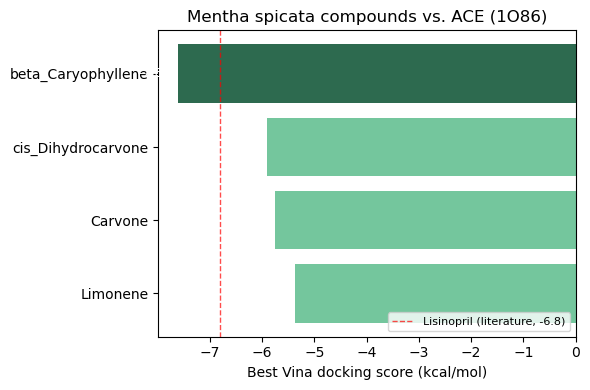

Saved figure: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/mentha_spicata_vs_ACE_scores.png


In [21]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#2d6a4f' if s == docking_df_spicata_ACE['Best_Vina_Score_kcal_mol'].min() else '#74c69d'
          for s in docking_df_spicata_ACE['Best_Vina_Score_kcal_mol']]
ax.barh(docking_df_spicata_ACE['Compound'], docking_df_spicata_ACE['Best_Vina_Score_kcal_mol'], color=colors)
ax.set_xlabel('Best Vina docking score (kcal/mol)')
ax.set_title('Mentha spicata compounds vs. ACE (1O86)')
ax.invert_yaxis()
for i, v in enumerate(docking_df_spicata_ACE['Best_Vina_Score_kcal_mol']):
    ax.text(v - 0.15, i, f"{v:.2f}", va='center', ha='right', fontsize=9, color='white')

# Reference line: lisinopril's published ACE docking score (-6.8 kcal/mol)
ax.axvline(-6.8, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Lisinopril (literature, -6.8)')
ax.legend(loc='lower right', fontsize=8)

plt.tight_layout()

fig_path_spicata_ACE = os.path.join(FIGURES_DIR, 'mentha_spicata_vs_ACE_scores.png')
plt.savefig(fig_path_spicata_ACE, dpi=300, bbox_inches='tight')
plt.show()
print("Saved figure:", fig_path_spicata_ACE)


### 7.8. ProLif interaction fingerprints -- Mentha_spicata vs ACE (each compound, own cell)

`n_jobs=1` avoids a multiprocessing/pickling crash in this environment;
`to_dataframe()` takes no arguments in ProLif 2.2.1.

In [22]:
prot_fp_universe = mda.Universe(RECEPTOR_PDB)

# Restrict to chain A only - chain B (2897 atoms vs A's 6309) is very likely
# a crystallographic symmetry mate, not part of the biological active site
# the ligand is docked into. This also sidesteps a ProLIF/MDAnalysis chain-
# labeling quirk that turns 'A'/'B' into '0'/'1' internally.
ag = prot_fp_universe.select_atoms("chainID A and resid > 0 and not resname UNK")

prot_fp = plf.Molecule.from_mda(ag, NoImplicit=False)
print(type(prot_fp))
chains_in_prot_fp = {r.chain for r in prot_fp.residues}
print("Chains in prot_fp:", chains_in_prot_fp)

SelectionError: Selection failed: 'Failed to parse value: >'

In [ ]:
prot_fp_universe = mda.Universe(RECEPTOR_PDB)
print("Chains/segids in raw universe:", set(prot_fp_universe.atoms.chainIDs))

In [ ]:
prot_fp_universe = mda.Universe(RECEPTOR_PDB)

print("Chains before filtering:", set(prot_fp_universe.atoms.chainIDs))
print("Chain A atoms:", len(prot_fp_universe.select_atoms("chainID A")))
print("Chain B atoms:", len(prot_fp_universe.select_atoms("chainID B")))

bad_mask = (prot_fp_universe.atoms.resids < 0) | (prot_fp_universe.atoms.resnames == "UNK")
ag = prot_fp_universe.atoms[~bad_mask]

print("Chain A atoms after filter:", len(ag.select_atoms("chainID A") if hasattr(ag, 'select_atoms') else [a for a in ag if a.chainID == 'A']))
print("Chains kept overall:", set(ag.chainIDs))

prot_fp = plf.Molecule.from_mda(ag, NoImplicit=False)
chains_in_prot_fp = {r.chain for r in prot_fp.residues}
print("Chains in final prot_fp:", chains_in_prot_fp)

In [ ]:
# ---- Helper: render a ProLIF LigNetwork widget to a real PNG file ----
import os
import sys
import subprocess

_RENDER_WORKER_PATH = os.path.join(os.getcwd(), "_lignetwork_render_worker.py")

_RENDER_WORKER_SOURCE = '''
import sys
from playwright.sync_api import sync_playwright

html_path, png_path, width, height, wait_ms = sys.argv[1:6]
width, height, wait_ms = int(width), int(height), int(wait_ms)

with sync_playwright() as p:
    browser = p.chromium.launch()
    page = browser.new_page(viewport={"width": width, "height": height})
    page.goto(f"file://{html_path}")
    page.wait_for_timeout(wait_ms)
    try:
        page.evaluate("if (typeof network !== 'undefined') { network.fit({animation:false}); }")
        page.wait_for_timeout(300)
    except Exception:
        pass
    page.screenshot(path=png_path)
    browser.close()
'''

def lignetwork_to_png(net, png_path, width=1000, height=800, wait_ms=1500):
    """Render a ProLIF LigNetwork object to a standalone PNG file."""
    with open(_RENDER_WORKER_PATH, "w") as f:
        f.write(_RENDER_WORKER_SOURCE)

    tmp_html = png_path.rsplit(".", 1)[0] + "_tmp.html"
    net.save(tmp_html)

    result = subprocess.run(
        [sys.executable, _RENDER_WORKER_PATH, os.path.abspath(tmp_html),
         os.path.abspath(png_path), str(width), str(height), str(wait_ms)],
        capture_output=True, text=True,
    )

    if result.returncode != 0:
        print("Render worker STDOUT:", result.stdout)
        print("Render worker STDERR:", result.stderr)
        raise RuntimeError(f"lignetwork_to_png failed for {png_path}")

    os.remove(tmp_html)
    print("Saved PNG:", png_path)

In [ ]:
# ---- ProLif: Carvone ----
lig_suppl_Carvone = list(plf.sdf_supplier(vina_out_sdf_Carvone))
fp_Carvone = plf.Fingerprint()
fp_Carvone.run_from_iterable(lig_suppl_Carvone, prot_fp, n_jobs=1)
results_df_Carvone = fp_Carvone.to_dataframe()
print("=== Carvone ===")
display(results_df_Carvone)

valid_frames = results_df_Carvone[results_df_Carvone.any(axis=1)].index

if len(valid_frames) == 0:
    print("No interactions detected in any pose for Carvone - skipping network plot.")
else:
    frame_to_use = valid_frames[0]
    print("Using frame:", frame_to_use)
    net_Carvone = fp_Carvone.plot_lignetwork(lig_suppl_Carvone[0], kind="frame", frame=frame_to_use, rotation=270)
    net_png_Carvone = os.path.join(FIGURES_DIR, "Carvone_1O86_2Dnetwork.png")
    lignetwork_to_png(net_Carvone, net_png_Carvone)

In [ ]:
# ---- ProLif: Limonene ----
lig_suppl_Limonene = list(plf.sdf_supplier(vina_out_sdf_Limonene))
fp_Limonene = plf.Fingerprint()
fp_Limonene.run_from_iterable(lig_suppl_Limonene, prot_fp, n_jobs=1)
results_df_Limonene = fp_Limonene.to_dataframe()
print("=== Limonene ===")
display(results_df_Limonene)

valid_frames = results_df_Limonene[results_df_Limonene.any(axis=1)].index

if len(valid_frames) == 0:
    print("No interactions detected in any pose for Limonene - skipping network plot.")
else:
    frame_to_use = valid_frames[0]
    print("Using frame:", frame_to_use)
    net_Limonene = fp_Limonene.plot_lignetwork(lig_suppl_Limonene[0], kind="frame", frame=frame_to_use, rotation=270)
    net_png_Limonene = os.path.join(FIGURES_DIR, "Limonene_CONFIRM_TARGET_2Dnetwork.png")  # <-- confirm this
    lignetwork_to_png(net_Limonene, net_png_Limonene)

In [ ]:
# ---- ProLif: cis_Dihydrocarvone ----
lig_suppl_cis_Dihydrocarvone = list(plf.sdf_supplier(vina_out_sdf_cis_Dihydrocarvone))
fp_cis_Dihydrocarvone = plf.Fingerprint()
fp_cis_Dihydrocarvone.run_from_iterable(lig_suppl_cis_Dihydrocarvone, prot_fp, n_jobs=1)
results_df_cis_Dihydrocarvone = fp_cis_Dihydrocarvone.to_dataframe()
print("=== cis_Dihydrocarvone ===")
display(results_df_cis_Dihydrocarvone)

valid_frames = results_df_cis_Dihydrocarvone[results_df_cis_Dihydrocarvone.any(axis=1)].index

if len(valid_frames) == 0:
    print("No interactions detected in any pose for cis_Dihydrocarvone - skipping network plot.")
else:
    frame_to_use = valid_frames[0]
    print("Using frame:", frame_to_use)
    net_cis_Dihydrocarvone = fp_cis_Dihydrocarvone.plot_lignetwork(lig_suppl_cis_Dihydrocarvone[0], kind="frame", frame=frame_to_use, rotation=270)
    net_png_cis_Dihydrocarvone = os.path.join(FIGURES_DIR, "cis_Dihydrocarvone_CONFIRM_TARGET_2Dnetwork.png")  # <-- confirm this
    lignetwork_to_png(net_cis_Dihydrocarvone, net_png_cis_Dihydrocarvone)

In [ ]:
# ---- ProLif: beta_Caryophyllene ----
lig_suppl_beta_Caryophyllene = list(plf.sdf_supplier(vina_out_sdf_beta_Caryophyllene))
fp_beta_Caryophyllene = plf.Fingerprint()
fp_beta_Caryophyllene.run_from_iterable(lig_suppl_beta_Caryophyllene, prot_fp, n_jobs=1)
results_df_beta_Caryophyllene = fp_beta_Caryophyllene.to_dataframe()
print("=== beta_Caryophyllene ===")
display(results_df_beta_Caryophyllene)

valid_frames = results_df_beta_Caryophyllene[results_df_beta_Caryophyllene.any(axis=1)].index

if len(valid_frames) == 0:
    print("No interactions detected in any pose for beta_Caryophyllene - skipping network plot.")
else:
    frame_to_use = valid_frames[0]
    print("Using frame:", frame_to_use)
    net_beta_Caryophyllene = fp_beta_Caryophyllene.plot_lignetwork(lig_suppl_beta_Caryophyllene[0], kind="frame", frame=frame_to_use, rotation=270)
    net_png_beta_Caryophyllene = os.path.join(FIGURES_DIR, "beta_Caryophyllene_CONFIRM_TARGET_2Dnetwork.png")  # <-- confirm this
    lignetwork_to_png(net_beta_Caryophyllene, net_png_beta_Caryophyllene)

### 7.9. Figure -- best-scoring compound vs. the real native ligand (lisinopril)

In [ ]:
best_row_spicata_ACE = docking_df_spicata_ACE.iloc[0]
best_compound_spicata_ACE = best_row_spicata_ACE['Compound']
print("Best-scoring compound:", best_compound_spicata_ACE, "|", best_row_spicata_ACE['Best_Vina_Score_kcal_mol'], "kcal/mol")

best_sdf_spicata_ACE = {
    "Carvone": vina_out_sdf_Carvone,
    "Limonene": vina_out_sdf_Limonene,
    "cis_Dihydrocarvone": vina_out_sdf_cis_Dihydrocarvone,
    "beta_Caryophyllene": vina_out_sdf_beta_Caryophyllene,
}[best_compound_spicata_ACE]

view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open(RECEPTOR_PDB,'r').read(), format='pdb')
Prot = view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW, {'opacity':0.6,'color':'white'})

view.addModel(open(NATIVE_LIG,'r').read(), format='mol2')
ref_m = view.getModel()
ref_m.setStyle({}, {'stick':{'colorscheme':'magentaCarbon','radius':0.2}})

results_spi_ACE = Chem.SDMolSupplier(best_sdf_spicata_ACE)
p_spi_ACE = Chem.MolToMolBlock(results_spi_ACE[0], False)
print('Reference (lisinopril): Magenta | Best compound pose: Cyan')
print('Pose: {} | Score: {}'.format(results_spi_ACE[0].GetProp('Pose'), results_spi_ACE[0].GetProp('Score')))

view.addModel(p_spi_ACE, 'mol')
x = view.getModel()
x.setStyle({}, {'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()
